## Credit Card Fraud Detection

### Exploratory Data Analysis

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, average_precision_score

In [72]:
df = pd.read_csv("credit_card_fraud_2026.csv")
df.head()

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0


In [73]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_id                20000 non-null  int64  
 1   amount_usd                    20000 non-null  float64
 2   merchant_category             20000 non-null  str    
 3   card_type                     20000 non-null  str    
 4   auth_method                   20000 non-null  str    
 5   channel                       20000 non-null  str    
 6   device_type                   20000 non-null  str    
 7   is_foreign_transaction        20000 non-null  bool   
 8   hours_since_last_txn          20000 non-null  float64
 9   txn_count_last_24h            20000 non-null  int64  
 10  distance_from_home_km         20000 non-null  float64
 11  card_age_months               20000 non-null  int64  
 12  customer_age                  20000 non-null  int64  
 13  account_bala

In [74]:
df.describe()

,transaction_id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,10000.500000,132.424597,8.950827,3.191650,22.139525,46.937550,49.669400,3316.662598,0.181300,19.807735,11.533650,2.998750,37.400390,0.281250,0.016950
std,5773.647028,256.963666,8.838745,1.779544,22.120960,6.768577,18.494032,4350.720948,0.422302,12.366301,6.925335,2.004956,17.061415,0.529209,0.129087
min,1.000000,1.000000,0.010000,0.000000,0.000000,22.000000,18.000000,52.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5000.750000,26.235000,2.590000,2.000000,6.337500,42.000000,34.000000,1019.140000,0.000000,10.700000,6.000000,1.000000,25.600000,0.000000,0.000000
50%,10000.500000,57.510000,6.210000,3.000000,15.505000,47.000000,50.000000,2007.685000,0.000000,18.800000,12.000000,3.000000,35.700000,0.000000,0.000000
75%,15000.250000,131.752500,12.432500,4.000000,30.820000,51.000000,66.000000,3944.120000,0.000000,27.600000,18.000000,5.000000,47.300000,0.000000,0.000000
max,20000.000000,6872.690000,87.050000,12.000000,216.190000,74.000000,81.000000,127125.860000,3.000000,74.400000,23.000000,6.000000,100.000000,4.000000,1.000000


In [75]:
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values:
 transaction_id                  0
amount_usd                      0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
is_ai_generated_scam_attempt    0
merchant_risk_score             0
prior_disputes                  0
is_fraud                        0
dtype: int64
Duplicate rows: 0


Fraud rate: 1.70%  (339 of 20000)
Accuracy of a "never fraud" model: 98.30%  <-- catches ZERO fraud


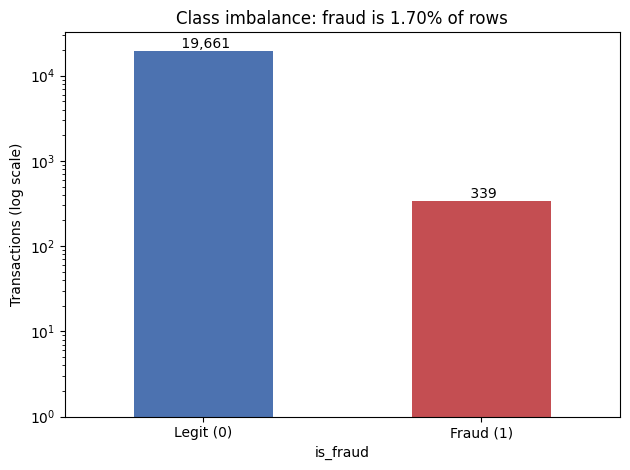

In [76]:
rate = df['is_fraud'].mean()
print(f'Fraud rate: {rate*100:.2f}%  ({df.is_fraud.sum()} of {len(df)})')
print(
    f'Accuracy of a "never fraud" model: {(1-rate)*100:.2f}%  <-- catches ZERO fraud')

counts = df['is_fraud'].value_counts().sort_index()
ax = counts.plot(kind='bar', color=['#4C72B0', '#C44E52'], log=True)
ax.set_xticklabels(['Legit (0)', 'Fraud (1)'], rotation=0)
ax.set_ylabel('Transactions (log scale)')
ax.set_title(f'Class imbalance: fraud is {rate*100:.2f}% of rows')
for i, v in enumerate(counts):
    ax.text(i, v, f' {v:,}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

### Test-Train Split

In [77]:
from sklearn.model_selection import train_test_split

# 1. Separate your features (X) and target variable (y)
# Drop non-feature columns like 'transaction_id' and the target 'is_fraud'
X = df.drop(columns=['transaction_id', 'is_fraud'])
y = df['is_fraud']

# 2. Perform the train-test split (e.g., 80% training, 20% testing)
# stratify=y preserves the class distribution of fraud cases in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Fraud cases in y_train: {y_train.sum()} ({y_train.mean():.2%})")
print(f"Fraud cases in y_test: {y_test.sum()} ({y_test.mean():.2%})")

Training set shape: (16000, 24)
Testing set shape: (4000, 24)
Fraud cases in y_train: 271 (1.69%)
Fraud cases in y_test: 68 (1.70%)


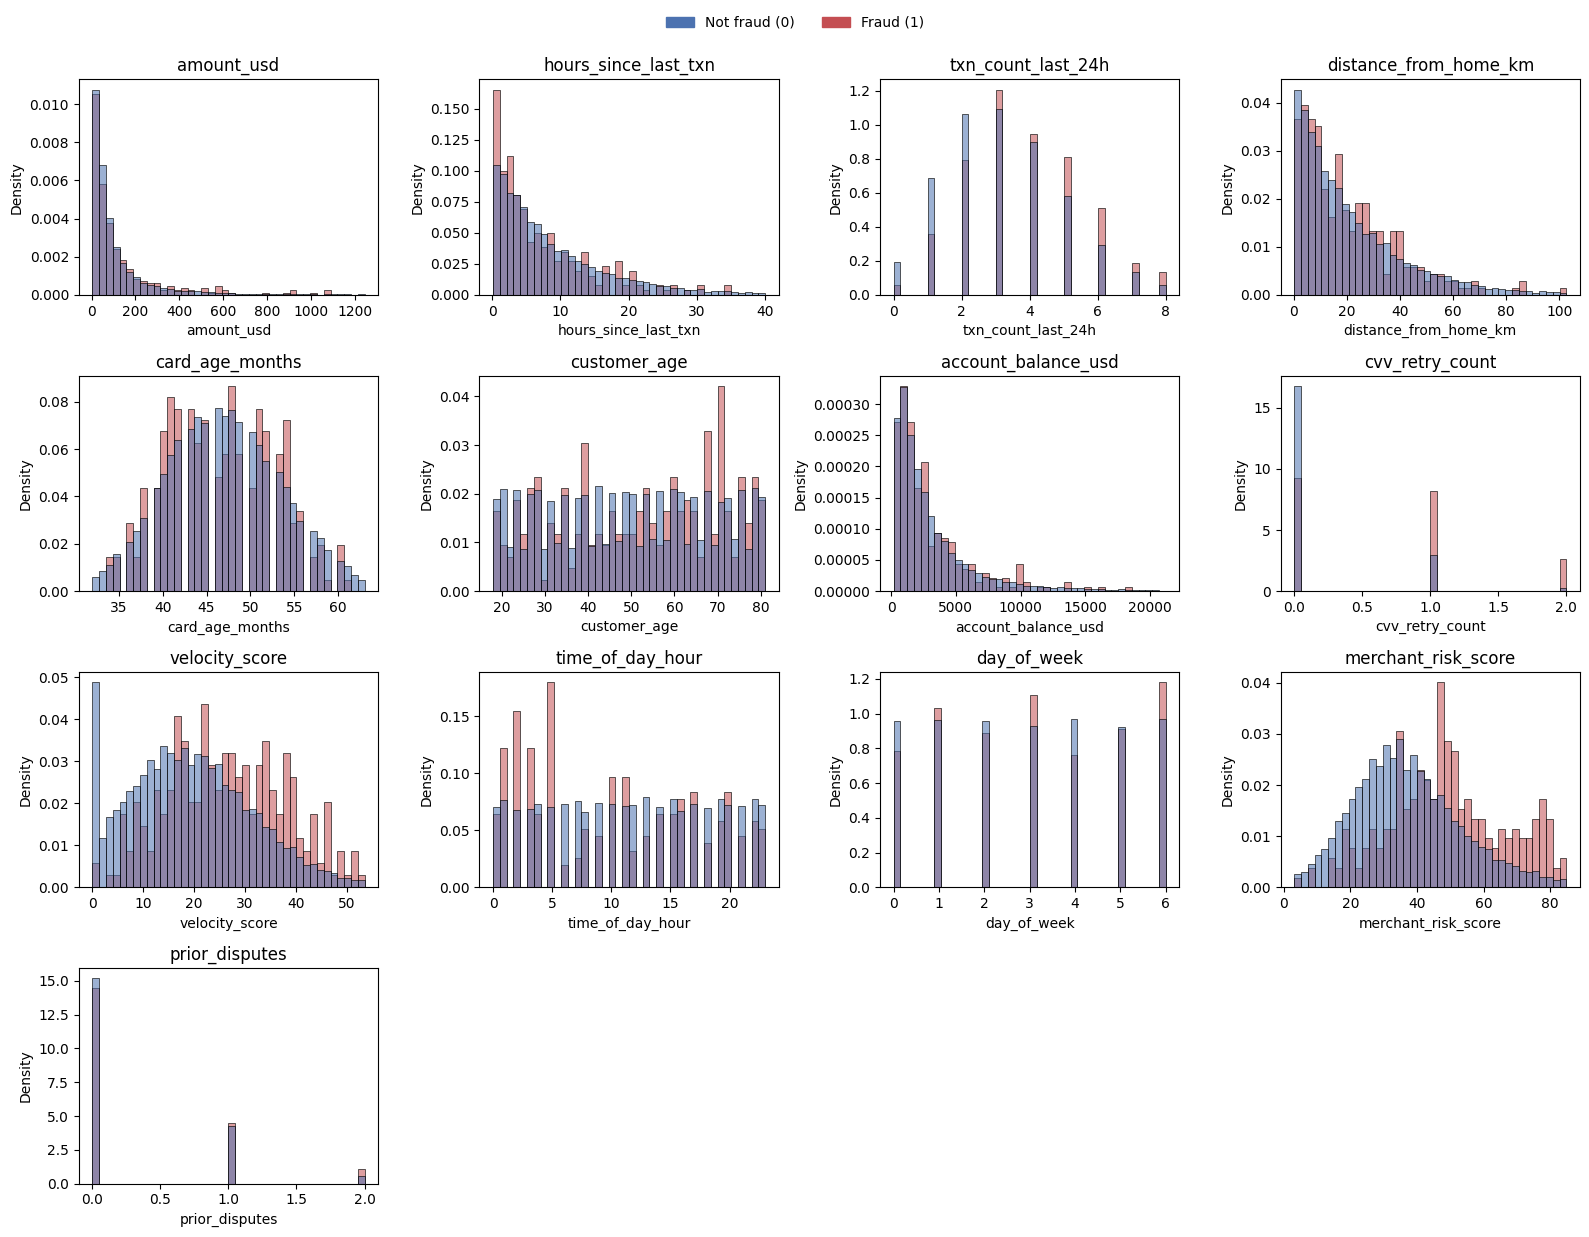

In [78]:
SEED = globals().get('SEED', 42)
TARGET = globals().get('TARGET', 'is_fraud')
C_OK = globals().get('C_OK', '#4C72B0')       # Blue for normal
C_FRAUD = globals().get('C_FRAUD', '#C44E52')  # Red for fraud
CLASS_PALETTE = globals().get('CLASS_PALETTE', {0: C_OK, 1: C_FRAUD})

# Ensure train dataframe is available (from your X_train/y_train split)
if 'train' not in globals():
    train = X_train.copy()
    train[TARGET] = y_train

# Use a sample for plotting so it stays fast on big data
eda = train.sample(min(len(train), 100_000), random_state=SEED)


def plot_grid(cols, plot_fn, ncols=4, size=(4, 3), legend=False):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(
        size[0] * ncols, size[1] * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, c in zip(axes, cols):
        plot_fn(c, ax)

    for ax in axes[len(cols):]:
        ax.axis("off")

    plt.tight_layout()

    if legend:
        from matplotlib.patches import Patch
        fig.legend(handles=[Patch(color=C_OK, label="Not fraud (0)"),
                            Patch(color=C_FRAUD, label="Fraud (1)")],
                   loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
    plt.show()


def plot_hist(c, ax):
    lo, hi = eda[c].quantile([0.01, 0.99])
    d = eda[eda[c].between(lo, hi)]
    sns.histplot(data=d, x=c, hue=TARGET, palette=CLASS_PALETTE, stat="density",
                 common_norm=False, bins=40, alpha=0.55, ax=ax, legend=False)
    ax.set_title(c)


# If auc_table or num_cols aren't defined, automatically infer numerical columns
if 'num_cols' not in globals():
    num_cols = eda.select_dtypes(
        include=[np.number]).columns.drop(TARGET, errors='ignore')

if 'auc_table' not in globals():
    # Fallback if auc_table doesn't exist yet
    top_num = list(num_cols)[:16]
else:
    top_num = [c for c in auc_table.index if c in num_cols][:16]

# Run the grid plot
plot_grid(top_num, plot_hist, legend=True)

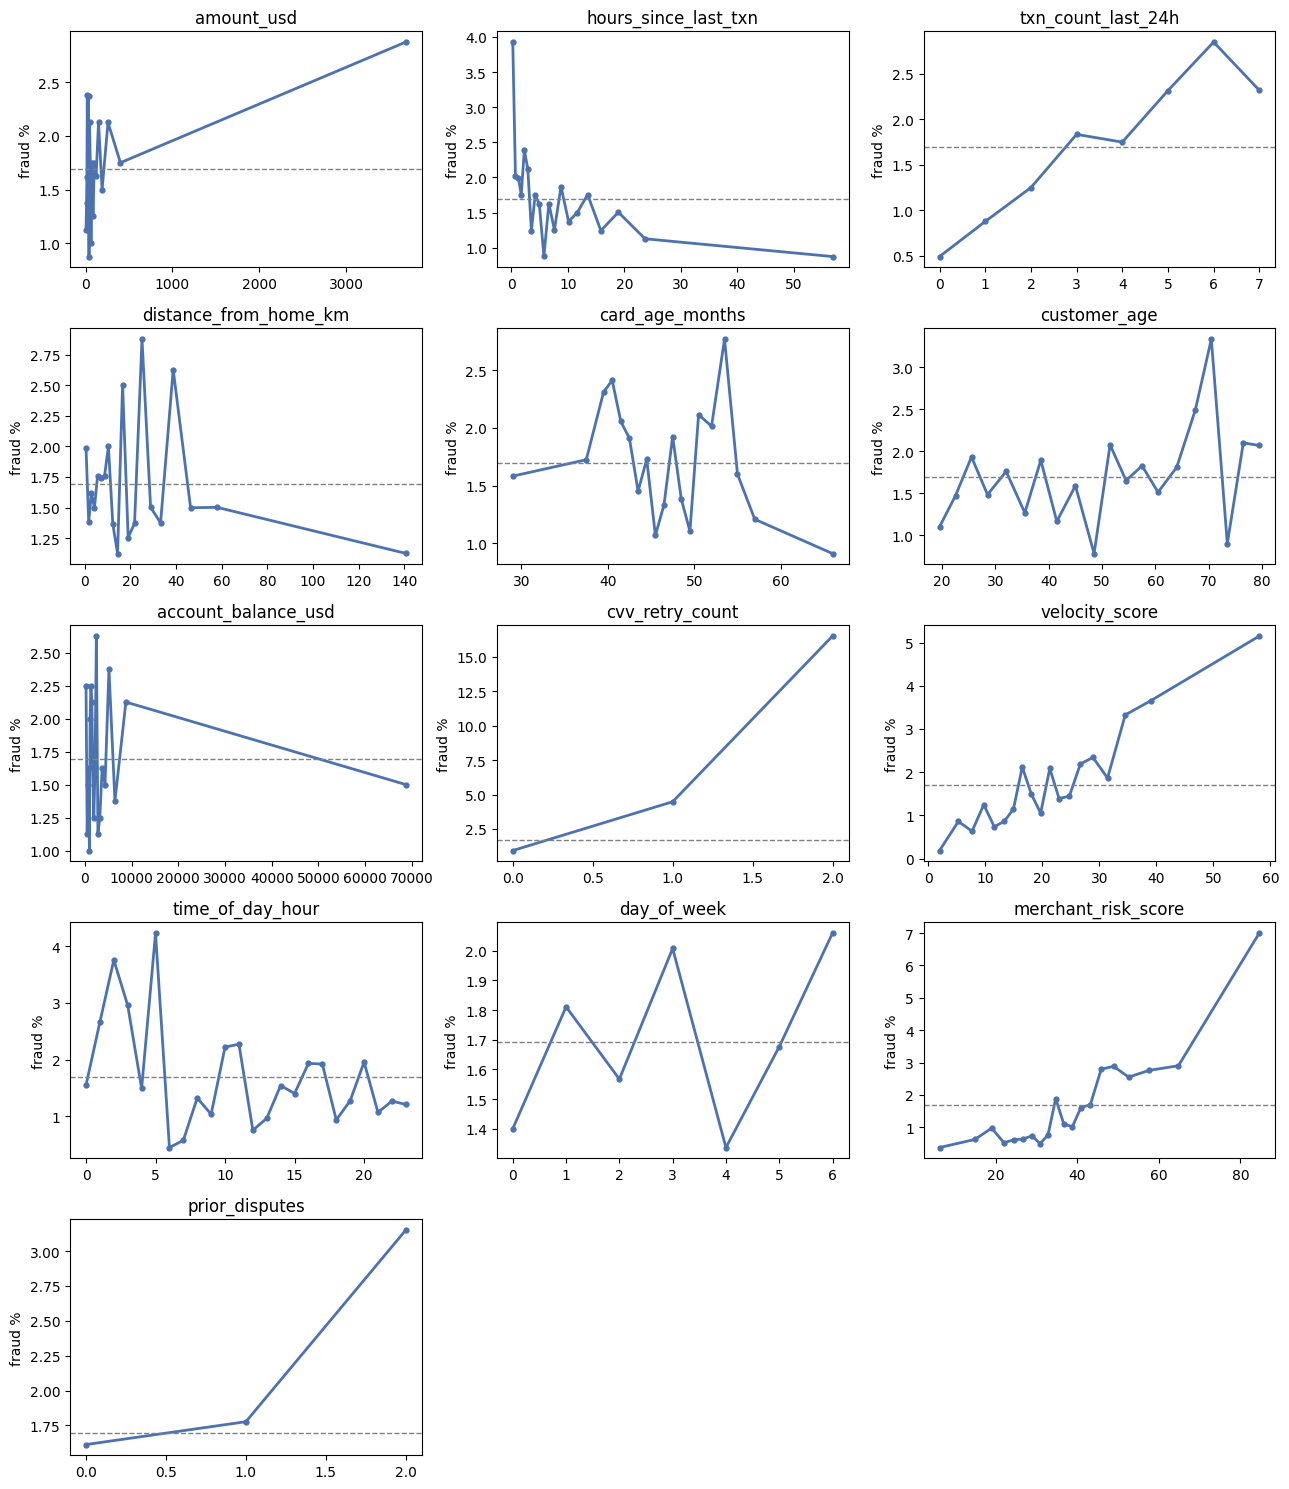

In [79]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 0. Define safe fallbacks for constants if not already defined in your notebook
TARGET = globals().get('TARGET', 'is_fraud')
C_TRAIN = globals().get('C_TRAIN', '#4C72B0')

# Ensure train dataframe is available
if 'train' not in globals():
    train = X_train.copy()
    train[TARGET] = y_train

base = train[TARGET].mean()

# Automatically infer NUM and LOG columns if they aren't defined in your session
if 'NUM' not in globals():
    NUM = list(train.select_dtypes(include=[np.number]).columns.drop(
        TARGET, errors='ignore'))[:15]

if 'LOG' not in globals():
    LOG = []  # Add column names here that need a log scale if desired

# 1. Helper function to compute binned or exact fraud rates


def fraud_rate_by(df, c, q=20):
    x = df[c]
    key = x if x.nunique() <= 30 else pd.qcut(
        x, q, duplicates="drop").apply(lambda iv: iv.mid)
    g = df.groupby(key, observed=True)[TARGET].agg(["mean", "size"])
    return g[g["size"] >= 200]


# 2. Plotting grid for numerical features
fig, axes = plt.subplots(5, 3, figsize=(13, 15))

for ax, c in zip(axes.flat, NUM):
    g = fraud_rate_by(train, c)
    ax.plot(g.index.astype(float), g["mean"] * 100,
            marker="o", ms=3.5, lw=2, color=C_TRAIN)
    ax.axhline(base * 100, ls="--", lw=1, color="grey")
    ax.set_title(c)
    ax.set_ylabel("fraud %")
    if c in LOG:
        ax.set_xscale("log")

# Turn off any unused subplots in the grid
for ax in axes.flat[len(NUM):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

cvv_retry_count is the clearest signal: each failed CVV attempt pushes the fraud rate up sharply. merchant_risk_score and velocity_score rise steadily, as expected. More transactions in the last 24h, or a very short gap since the last transaction, also mean more fraud. customer_age has a visible pattern too. Distance, card age, balance, hour and weekday look flat on their own.

In [5]:
# 0. Define safe fallbacks for constants if not already defined in your notebook
TARGET = globals().get('TARGET', 'is_fraud')
C_OK = globals().get('C_OK', '#4C72B0')       # Blue for normal
C_FRAUD = globals().get('C_FRAUD', '#C44E52')  # Red for fraud

# Ensure train dataframe and baseline rate are available
if 'train' not in globals():
    train = X_train.copy()
    train[TARGET] = y_train

rate = train[TARGET].mean()

# Automatically detect boolean and categorical columns if not already defined
if 'bool_cols' not in globals():
    bool_cols = [col for col in train.columns if train[col].nunique()
                 == 2 and col != TARGET]

if 'cat_cols' not in globals():
    cat_cols = [col for col in train.select_dtypes(
        include=['object', 'category']).columns if col != TARGET]

# Re-verify plot_grid helper function in case it wasn't run in the current session
if 'plot_grid' not in globals():
    def plot_grid(cols, plot_fn, ncols=4, size=(4, 3), legend=False):
        nrows = int(np.ceil(len(cols) / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(
            size[0] * ncols, size[1] * nrows))
        axes = np.array(axes).reshape(-1)

        for ax, c in zip(axes, cols):
            plot_fn(c, ax)

        for ax in axes[len(cols):]:
            ax.axis("off")

        plt.tight_layout()
        plt.show()

# Define the plotting function for categorical/boolean rates


def plot_rate(c, ax):
    d = train[[c, TARGET]].copy()
    d[c] = d[c].astype(str)
    top = d[c].value_counts().head(8).index
    r = d[d[c].isin(top)].groupby(c)[TARGET].mean()
    colors = [C_FRAUD if v > rate else C_OK for v in r.values]
    ax.bar(r.index, r.values, color=colors)
    ax.axhline(rate, color="#111827", ls="--", lw=1.5)
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=45)


# Execute plots for boolean and categorical features
if bool_cols:
    print("Boolean-like features")
    plot_grid(bool_cols[:12], plot_rate)

if cat_cols:
    print("Categorical / text features")
    plot_grid(cat_cols[:12], plot_rate)

NameError: name 'X_train' is not defined

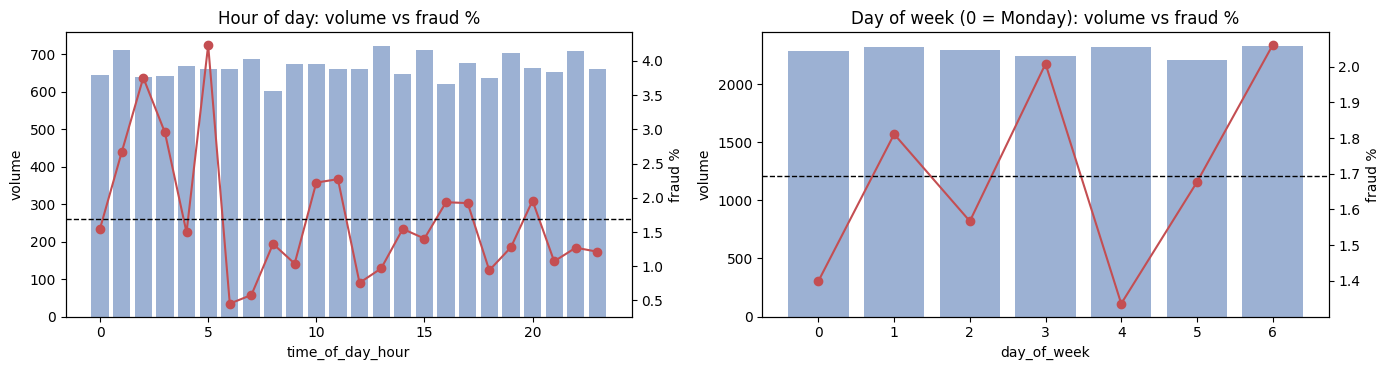

hour of day : peak 5h at 4.23% = 2.50x baseline | lowest 6h = 0.27x
day of week : max 1.22x | min 0.79x baseline
=> there is a real time-of-day effect - worth explicit time features


In [81]:
import matplotlib.pyplot as plt
import pandas as pd

# Define your target column name based on your split
TARGET = 'is_fraud'

# Combine X_train and y_train for safe training-set analysis
train_df = X_train.copy()
train_df[TARGET] = y_train

# Calculate baseline fraud rate strictly from the training split
rate = y_train.mean()

# Plotting volume vs fraud % by hour and day of week
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, col, title in [(axes[0], "time_of_day_hour", "Hour of day"), (axes[1], "day_of_week", "Day of week (0 = Monday)")]:
    g = train_df.groupby(col)[TARGET].agg(["mean", "size"])
    ax.bar(g.index, g["size"], color="#4C72B0", alpha=.55)
    ax.set_ylabel("volume")
    ax.set_xlabel(col)
    ax2 = ax.twinx()
    ax2.plot(g.index, g["mean"] * 100, "o-", c="#C44E52")
    ax2.set_ylabel("fraud %")
    ax2.axhline(rate * 100, ls="--", c="k", lw=1)
    ax.set_title(f"{title}: volume vs fraud %")

plt.tight_layout()
plt.show()

# Statistical breakdown
hr = train_df.groupby("time_of_day_hour")[TARGET].mean()
dw = train_df.groupby("day_of_week")[TARGET].mean()

print(f"hour of day : peak {hr.idxmax()}h at {hr.max():.2%} = {hr.max() / rate:.2f}x baseline | lowest {hr.idxmin()}h = {hr.min() / rate:.2f}x")
print(
    f"day of week : max {dw.max() / rate:.2f}x | min {dw.min() / rate:.2f}x baseline")
print("=> " + ("the clock effect is essentially flat in this data - time features will matter little" if hr.max() / rate < 1.3
               else "there is a real time-of-day effect - worth explicit time features"))

### Encoding Variables

In [82]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# 1. Automatically identify column types from X_train
# Boolean columns and categorical columns
bool_cols = X_train.select_dtypes(include=['bool']).columns.tolist()
cat_cols = X_train.select_dtypes(
    include=['object', 'category']).columns.tolist()
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"Numerical columns: {num_cols}")
print(f"Boolean columns: {bool_cols}")
print(f"Categorical columns: {cat_cols}")

# 2. Build the preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        # Convert booleans to integers (0 and 1)
        ('bool', 'passthrough', bool_cols),
        # One-hot encode categorical columns, ignoring unseen categories in test set
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ],
    remainder='passthrough'  # Keeps numerical columns as they are
)

# 3. Fit on training data and transform both train and test data
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

Numerical columns: ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']
Boolean columns: ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']
Categorical columns: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']


C:\Users\Ruby\AppData\Local\Temp\ipykernel_4904\2168150070.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(


In [3]:
# df_encoded.head()

### Model Fitting

#### Random Forest

In [84]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# 1. Initialize the Random Forest with class penalties
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',          # Handles the class imbalance automatically
    random_state=42,
    n_jobs=-1                         # Uses all available CPU cores for faster training
)

# 2. Fit the model on your encoded training data
rf_model.fit(X_train_encoded, y_train)

# 3. Make predictions on the test set
y_pred = rf_model.predict(X_test_encoded)
# Probability of fraud (class 1)
y_prob = rf_model.predict_proba(X_test_encoded)[:, 1]

# 4. Evaluate performance
print("Classification Report:")
print(classification_report(y_test, y_pred))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3932
           1       0.00      0.00      0.00        68

    accuracy                           0.98      4000
   macro avg       0.49      0.50      0.50      4000
weighted avg       0.97      0.98      0.97      4000

ROC-AUC Score: 0.9064


C:\Users\Ruby\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Ruby\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Ruby\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

In [85]:
import numpy as np
from sklearn.metrics import precision_recall_curve, classification_report

# 1. Get the predicted probabilities for fraud (Class 1)
# (If you are using the pipeline, use: y_prob = fraud_pipeline.predict_proba(X_test)[:, 1])
y_prob = rf_model.predict_proba(X_test_encoded)[:, 1]

# 2. Calculate precision, recall, and thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)

# 3. Find the threshold that maximizes the F1-score
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Optimal Decision Threshold: {best_threshold:.4f}")

# 4. Apply the new threshold to make predictions
y_pred_custom = (y_prob >= best_threshold).astype(int)

# 5. Evaluate with the new threshold
print("\nClassification Report with Optimized Threshold:")
print(classification_report(y_test, y_pred_custom))

Optimal Decision Threshold: 0.1700

Classification Report with Optimized Threshold:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      3932
           1       0.20      0.40      0.27        68

    accuracy                           0.96      4000
   macro avg       0.59      0.68      0.62      4000
weighted avg       0.98      0.96      0.97      4000



--- Random Forest Top 10 Feature Importances ---


,Feature,Importance
0,merchant_risk_score,0.115493
1,cvv_retry_count,0.101793
2,velocity_score,0.083437
3,ip_country_mismatch,0.052029
4,hours_since_last_txn,0.049851
5,amount_usd,0.040351
6,auth_method_No Authentication,0.040057
7,time_of_day_hour,0.039385
8,distance_from_home_km,0.039289
9,customer_age,0.037897


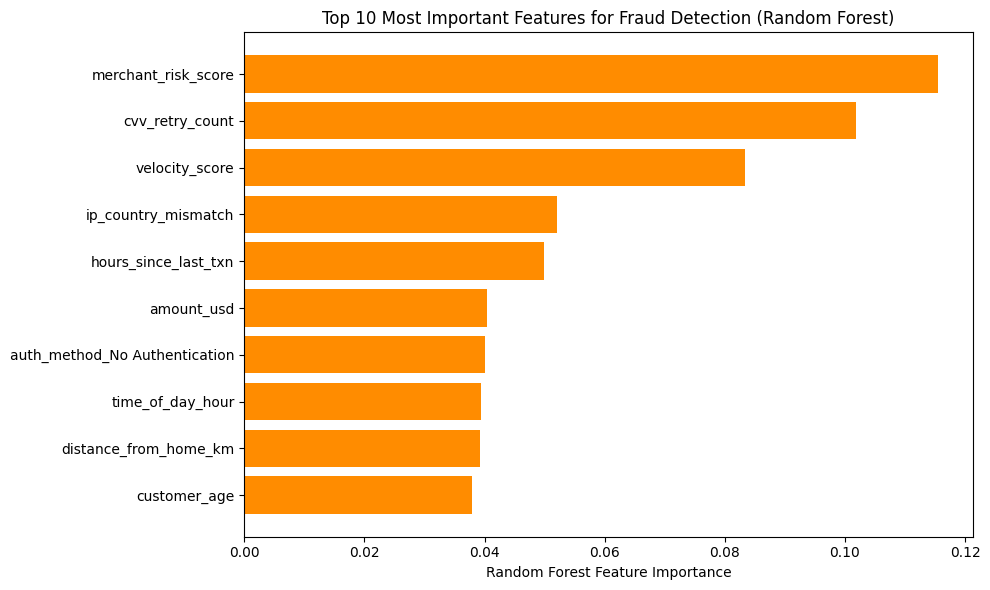

In [86]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Get feature names from the preprocessor & importances
feature_names = preprocessor.get_feature_names_out()
importances = rf_model.feature_importances_

# 2. Create a dataframe and clean up names
rf_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

rf_imp_df['Feature'] = rf_imp_df['Feature'].str.replace(
    r'^(cat__|bool__|remainder__)', '', regex=True)

# 3. Display the top 10 as a table
print("--- Random Forest Top 10 Feature Importances ---")
display(rf_imp_df.head(10))

# 4. Plot top 10
plt.figure(figsize=(10, 6))
top_rf = rf_imp_df.head(10)
plt.barh(top_rf['Feature'][::-1], top_rf['Importance']
         [::-1], color='darkorange')
plt.xlabel("Random Forest Feature Importance")
plt.title("Top 10 Most Important Features for Fraud Detection (Random Forest)")
plt.tight_layout()
plt.show()

#### XGBoost

In [87]:
import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score

# 1. Calculate scale_pos_weight for class imbalance
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_val = neg_count / pos_count

# 2. Initialize and train XGBoost
xgb_model = XGBClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=scale_pos_weight_val,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_encoded, y_train)

# 3. Predict probabilities on test set
y_prob_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]
print(f"XGBoost ROC-AUC Score: {roc_auc_score(y_test, y_prob_xgb):.4f}")

# 4. Find the optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_xgb)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold_xgb = thresholds[best_idx]

print(f"Optimal XGBoost Decision Threshold: {best_threshold_xgb:.4f}")

# 5. Apply threshold and print classification report
y_pred_xgb_custom = (y_prob_xgb >= best_threshold_xgb).astype(int)

print("\nXGBoost Classification Report with Optimized Threshold:")
print(classification_report(y_test, y_pred_xgb_custom))

XGBoost ROC-AUC Score: 0.8820
Optimal XGBoost Decision Threshold: 0.6598

XGBoost Classification Report with Optimized Threshold:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      3932
           1       0.23      0.32      0.27        68

    accuracy                           0.97      4000
   macro avg       0.61      0.65      0.63      4000
weighted avg       0.98      0.97      0.97      4000



--- XGBoost Top 10 Feature Importances ---


,Feature,Importance
0,cvv_retry_count,0.101897
1,ip_country_mismatch,0.079136
2,auth_method_No Authentication,0.058407
3,is_new_merchant,0.054287
4,billing_shipping_mismatch,0.052968
5,is_foreign_transaction,0.044095
6,merchant_risk_score,0.040173
7,used_vpn,0.036143
8,velocity_score,0.029107
9,auth_method_Biometric,0.026555


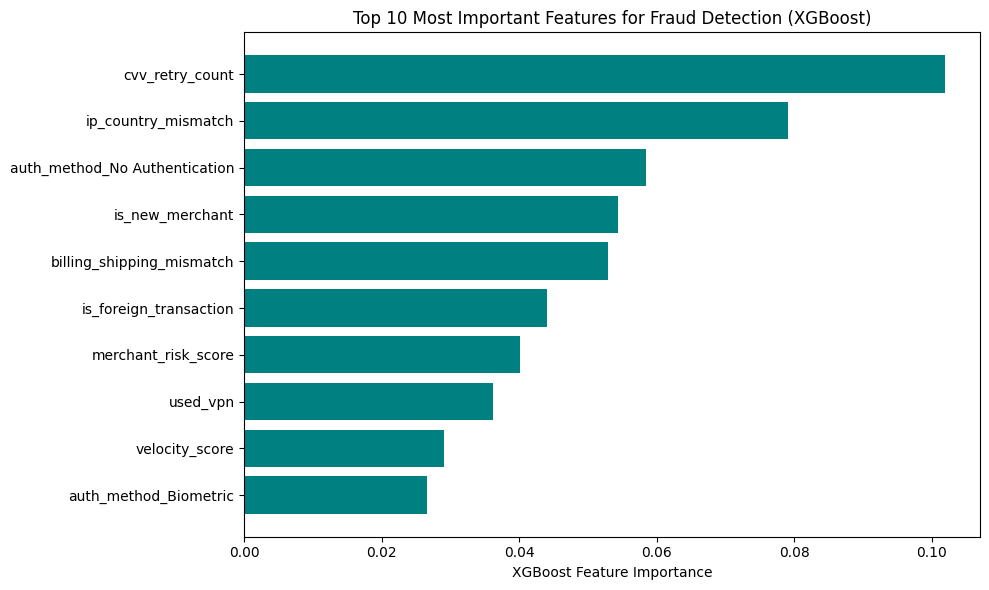

In [88]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Get feature names from the preprocessor & importances
feature_names = preprocessor.get_feature_names_out()
importances = xgb_model.feature_importances_

# 2. Create a dataframe and clean up names
xgb_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

xgb_imp_df['Feature'] = xgb_imp_df['Feature'].str.replace(
    r'^(cat__|bool__|remainder__)', '', regex=True)

# 3. Display the top 10 as a table
print("--- XGBoost Top 10 Feature Importances ---")
display(xgb_imp_df.head(10))

# 4. Plot top 10
plt.figure(figsize=(10, 6))
top_xgb = xgb_imp_df.head(10)
plt.barh(top_xgb['Feature'][::-1], top_xgb['Importance'][::-1], color='teal')
plt.xlabel("XGBoost Feature Importance")
plt.title("Top 10 Most Important Features for Fraud Detection (XGBoost)")
plt.tight_layout()
plt.show()

#### Decision tree

Decision Tree ROC-AUC Score: 0.5305
Optimal Decision Tree Threshold: 1.0000

Decision Tree Classification Report with Optimized Threshold:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      3932
           1       0.09      0.07      0.08        68

    accuracy                           0.97      4000
   macro avg       0.54      0.53      0.53      4000
weighted avg       0.97      0.97      0.97      4000


--- Decision Tree Top 10 Feature Importances ---


,Feature,Importance
0,cvv_retry_count,0.165347
1,merchant_risk_score,0.146809
2,ip_country_mismatch,0.103311
3,velocity_score,0.088515
4,hours_since_last_txn,0.052680
5,card_age_months,0.043047
6,distance_from_home_km,0.037248
7,amount_usd,0.037245
8,time_of_day_hour,0.036172
9,auth_method_No Authentication,0.035066


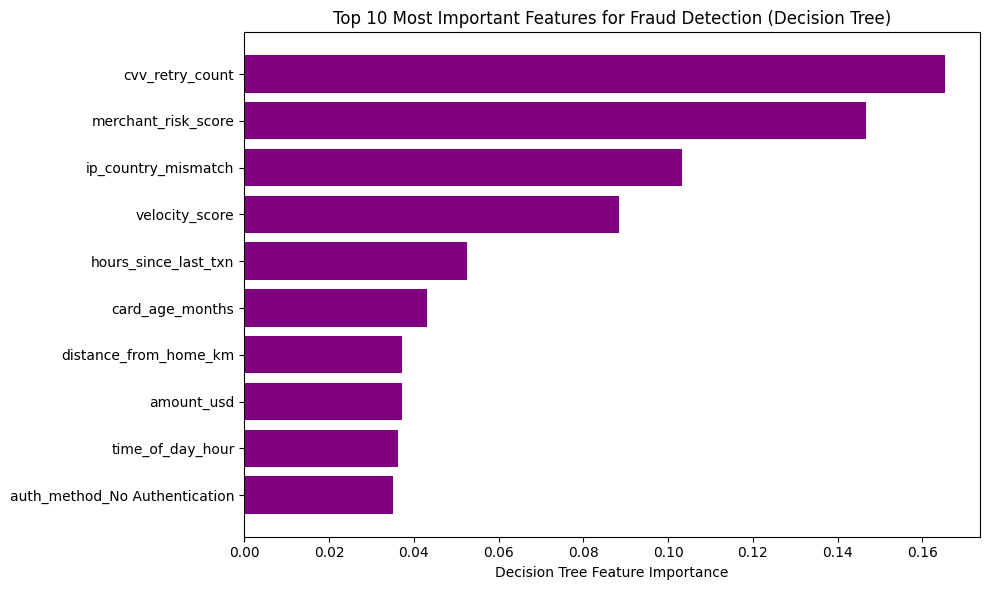

In [89]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score

# 1. Initialize and train Decision Tree with class penalties
dt_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

dt_model.fit(X_train_encoded, y_train)

# 2. Predict probabilities on test set
y_prob_dt = dt_model.predict_proba(X_test_encoded)[:, 1]
print(f"Decision Tree ROC-AUC Score: {roc_auc_score(y_test, y_prob_dt):.4f}")

# 3. Find the optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_dt)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold_dt = thresholds[best_idx]

print(f"Optimal Decision Tree Threshold: {best_threshold_dt:.4f}")

# 4. Apply threshold and print classification report
y_pred_dt_custom = (y_prob_dt >= best_threshold_dt).astype(int)

print("\nDecision Tree Classification Report with Optimized Threshold:")
print(classification_report(y_test, y_pred_dt_custom))

# 5. Feature Importances (Table + Plot)
feature_names = preprocessor.get_feature_names_out()
importances = dt_model.feature_importances_

dt_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Clean up prefixes
dt_imp_df['Feature'] = dt_imp_df['Feature'].str.replace(
    r'^(cat__|bool__|remainder__)', '', regex=True)

# Display table
print("\n--- Decision Tree Top 10 Feature Importances ---")
display(dt_imp_df.head(10))

# Plot top 10
plt.figure(figsize=(10, 6))
top_dt = dt_imp_df.head(10)
plt.barh(top_dt['Feature'][::-1], top_dt['Importance'][::-1], color='purple')
plt.xlabel("Decision Tree Feature Importance")
plt.title("Top 10 Most Important Features for Fraud Detection (Decision Tree)")
plt.tight_layout()
plt.show()

#### LightGBM

LightGBM ROC-AUC Score: 0.8953
Optimal LightGBM Decision Threshold: 0.6793

LightGBM Classification Report with Optimized Threshold:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3932
           1       0.25      0.35      0.29        68

    accuracy                           0.97      4000
   macro avg       0.62      0.67      0.64      4000
weighted avg       0.98      0.97      0.97      4000


--- LightGBM Top 10 Feature Importances ---


,Feature,Importance
0,merchant_risk_score,528
1,velocity_score,479
2,amount_usd,245
3,account_balance_usd,241
4,cvv_retry_count,239
5,time_of_day_hour,212
6,distance_from_home_km,199
7,hours_since_last_txn,194
8,customer_age,164
9,ip_country_mismatch,150


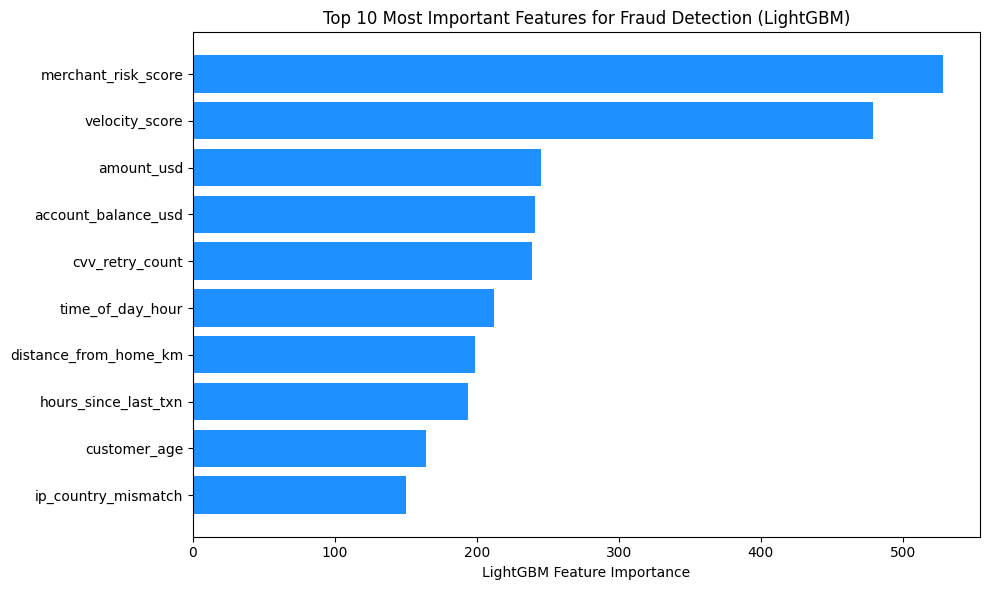

In [90]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score

# 1. Initialize and train LightGBM with class balancing
lgb_model = LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    class_weight='balanced',  # Automatically handles class imbalance
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

lgb_model.fit(X_train_encoded, y_train)

# 2. Predict probabilities on test set
y_prob_lgb = lgb_model.predict_proba(X_test_encoded)[:, 1]
print(f"LightGBM ROC-AUC Score: {roc_auc_score(y_test, y_prob_lgb):.4f}")

# 3. Find the optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_lgb)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold_lgb = thresholds[best_idx]

print(f"Optimal LightGBM Decision Threshold: {best_threshold_lgb:.4f}")

# 4. Apply threshold and print classification report
y_pred_lgb_custom = (y_prob_lgb >= best_threshold_lgb).astype(int)

print("\nLightGBM Classification Report with Optimized Threshold:")
print(classification_report(y_test, y_pred_lgb_custom))

# 5. Feature Importances (Table + Plot)
feature_names = preprocessor.get_feature_names_out()
importances = lgb_model.feature_importances_

lgb_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Clean up prefixes
lgb_imp_df['Feature'] = lgb_imp_df['Feature'].str.replace(
    r'^(cat__|bool__|remainder__)', '', regex=True)

# Display table
print("\n--- LightGBM Top 10 Feature Importances ---")
display(lgb_imp_df.head(10))

# Plot top 10
plt.figure(figsize=(10, 6))
top_lgb = lgb_imp_df.head(10)
plt.barh(top_lgb['Feature'][::-1], top_lgb['Importance']
         [::-1], color='dodgerblue')
plt.xlabel("LightGBM Feature Importance")
plt.title("Top 10 Most Important Features for Fraud Detection (LightGBM)")
plt.tight_layout()
plt.show()

#### CatBoost

In [91]:
pip install catboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


CatBoost ROC-AUC Score: 0.9337
Optimal CatBoost Decision Threshold: 0.7035

CatBoost Classification Report with Optimized Threshold:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3932
           1       0.32      0.57      0.41        68

    accuracy                           0.97      4000
   macro avg       0.66      0.78      0.70      4000
weighted avg       0.98      0.97      0.98      4000


--- CatBoost Top 10 Feature Importances ---


,Feature,Importance
0,cvv_retry_count,12.507017
1,velocity_score,12.219792
2,merchant_risk_score,11.632562
3,ip_country_mismatch,7.095950
4,auth_method_No Authentication,5.298559
5,time_of_day_hour,4.695456
6,billing_shipping_mismatch,4.477854
7,is_new_merchant,4.049664
8,hours_since_last_txn,3.358141
9,auth_method_PIN,2.652578


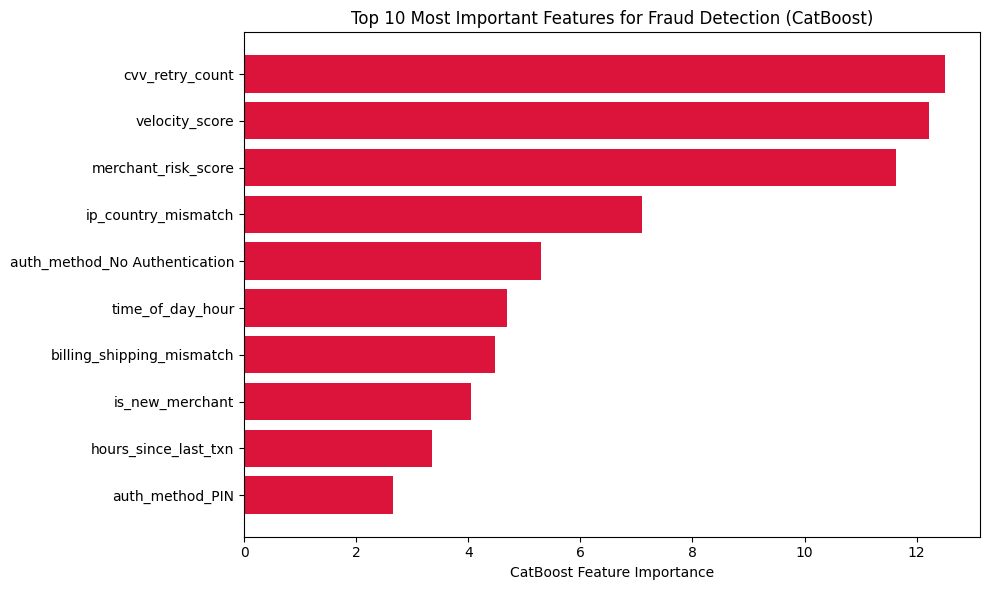

In [112]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score

# 1. Initialize and train CatBoost with class balancing
cat_model = CatBoostClassifier(
    iterations=150,
    learning_rate=0.05,
    depth=5,
    auto_class_weights='Balanced',  # CatBoost's built-in handling for class imbalance
    random_seed=42,
    thread_count=-1,
    verbose=0
)

cat_model.fit(X_train_encoded, y_train)

# 2. Predict probabilities on test set
y_prob_cat = cat_model.predict_proba(X_test_encoded)[:, 1]
print(f"CatBoost ROC-AUC Score: {roc_auc_score(y_test, y_prob_cat):.4f}")

# 3. Find the optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_cat)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold_cat = thresholds[best_idx]

print(f"Optimal CatBoost Decision Threshold: {best_threshold_cat:.4f}")

# 4. Apply threshold and print classification report
y_pred_cat_custom = (y_prob_cat >= best_threshold_cat).astype(int)

print("\nCatBoost Classification Report with Optimized Threshold:")
print(classification_report(y_test, y_pred_cat_custom))

# 5. Feature Importances (Table + Plot)
feature_names = X_train_encoded.columns if hasattr(
    X_train_encoded, 'columns') else preprocessor.get_feature_names_out()
importances = cat_model.get_feature_importance()

cat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Clean up prefixes
cat_imp_df['Feature'] = cat_imp_df['Feature'].str.replace(
    r'^(cat__|bool__|remainder__)', '', regex=True)

# Display table
print("\n--- CatBoost Top 10 Feature Importances ---")
display(cat_imp_df.head(10))

# Plot top 10
plt.figure(figsize=(10, 6))
top_cat = cat_imp_df.head(10)
plt.barh(top_cat['Feature'][::-1],
         top_cat['Importance'][::-1], color='crimson')
plt.xlabel("CatBoost Feature Importance")
plt.title("Top 10 Most Important Features for Fraud Detection (CatBoost)")
plt.tight_layout()
plt.show()

#### Summary

In [93]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

# Define the dictionary of your trained models
# (If you used the regularized pruned decision tree, replace dt_model with dt_pruned)
models = {
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgb_model,
    'Decision Tree': dt_model,
    'CatBoost': cat_model
}

results = []

for name, model in models.items():
    # 1. Get predicted probabilities for the positive (fraud) class
    y_prob = model.predict_proba(X_test_encoded)[:, 1]

    # 2. Calculate ROC-AUC
    roc_auc = roc_auc_score(y_test, y_prob)

    # 3. Find optimal decision threshold maximizing F1-score
    precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(
        thresholds) else 0.5

    # 4. Apply the optimal threshold
    y_pred = (y_prob >= best_threshold).astype(int)

    # 5. Extract metrics for Class 1 (Fraud)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average=None, zero_division=0)

    fraud_precision = precision[1] if len(precision) > 1 else 0.0
    fraud_recall = recall[1] if len(recall) > 1 else 0.0
    fraud_f1 = f1[1] if len(f1) > 1 else 0.0

    # Store results
    results.append({
        'Model': name,
        'ROC-AUC': round(roc_auc, 4),
        'Opt Threshold': round(best_threshold, 4),
        'Fraud Precision': round(fraud_precision, 4),
        'Fraud Recall': round(fraud_recall, 4),
        'Fraud F1-Score': round(fraud_f1, 4)
    })

# Convert to DataFrame and sort by ROC-AUC
summary_df = pd.DataFrame(results).sort_values(
    by='ROC-AUC', ascending=False).reset_index(drop=True)

# Display the summary comparison table
print("--- Model Performance Comparison Summary ---")
display(summary_df)

--- Model Performance Comparison Summary ---


,Model,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,CatBoost,0.9337,0.7035,0.3197,0.5735,0.4105
1,Random Forest,0.9064,0.1700,0.2000,0.3971,0.2660
2,LightGBM,0.8953,0.6793,0.2474,0.3529,0.2909
3,XGBoost,0.8820,0.6598,0.2292,0.3235,0.2683
4,Decision Tree,0.5305,1.0000,0.0926,0.0735,0.0820


#### Ensemble Voting

In [94]:
import numpy as np
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score

# 1. Get probabilities from each trained model
y_prob_cat = cat_model.predict_proba(X_test_encoded)[:, 1]
y_prob_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]
y_prob_lgb = lgb_model.predict_proba(X_test_encoded)[:, 1]

# 2. Average them together for soft voting
y_prob_voting = (y_prob_cat + y_prob_xgb + y_prob_lgb) / 3

# 3. Print ROC-AUC Score
print(
    f"Ensemble Voting ROC-AUC Score: {roc_auc_score(y_test, y_prob_voting):.4f}")

# 4. Find the optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_voting)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold_voting = thresholds[best_idx] if best_idx < len(
    thresholds) else 0.5

print(f"Optimal Voting Decision Threshold: {best_threshold_voting:.4f}")

# 5. Apply the threshold and print the classification report
y_pred_voting_custom = (y_prob_voting >= best_threshold_voting).astype(int)

print("\nEnsemble Voting Classification Report with Optimized Threshold:")
print(classification_report(y_test, y_pred_voting_custom))

Ensemble Voting ROC-AUC Score: 0.9176
Optimal Voting Decision Threshold: 0.6920

Ensemble Voting Classification Report with Optimized Threshold:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3932
           1       0.28      0.37      0.32        68

    accuracy                           0.97      4000
   macro avg       0.63      0.68      0.65      4000
weighted avg       0.98      0.97      0.97      4000



#### Summary

In [95]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

# 1. Calculate ensemble probabilities
y_prob_rf = rf_model.predict_proba(X_test_encoded)[:, 1]
y_prob_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]
y_prob_lgb = lgb_model.predict_proba(X_test_encoded)[:, 1]
y_prob_voting = (y_prob_rf + y_prob_xgb + y_prob_lgb) / 3

# Define all models including the ensemble
models = {
    'Random Forest': rf_model.predict_proba(X_test_encoded)[:, 1],
    'LightGBM': y_prob_lgb,
    'XGBoost': y_prob_xgb,
    'Ensemble Voting': y_prob_voting,
    'Decision Tree': dt_model.predict_proba(X_test_encoded)[:, 1],
    'CatBoost': y_prob_cat
}

results = []

for name, y_prob in models.items():
    # 2. Calculate ROC-AUC
    roc_auc = roc_auc_score(y_test, y_prob)

    # 3. Find optimal decision threshold maximizing F1-score
    precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(
        thresholds) else 0.5

    # 4. Apply the optimal threshold
    y_pred = (y_prob >= best_threshold).astype(int)

    # 5. Extract metrics for Class 1 (Fraud)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average=None, zero_division=0)

    fraud_precision = precision[1] if len(precision) > 1 else 0.0
    fraud_recall = recall[1] if len(recall) > 1 else 0.0
    fraud_f1 = f1[1] if len(f1) > 1 else 0.0

    # Store results
    results.append({
        'Model': name,
        'ROC-AUC': round(roc_auc, 4),
        'Opt Threshold': round(best_threshold, 4),
        'Fraud Precision': round(fraud_precision, 4),
        'Fraud Recall': round(fraud_recall, 4),
        'Fraud F1-Score': round(fraud_f1, 4)
    })

# Convert to DataFrame and sort by ROC-AUC
summary_df = pd.DataFrame(results).sort_values(
    by='ROC-AUC', ascending=False).reset_index(drop=True)

# Display final comparison table
print("--- Final Model Performance Comparison Summary ---")
display(summary_df)

--- Final Model Performance Comparison Summary ---


,Model,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,CatBoost,0.9337,0.7035,0.3197,0.5735,0.4105
1,Random Forest,0.9064,0.1700,0.2000,0.3971,0.2660
2,Ensemble Voting,0.8997,0.5471,0.2794,0.2794,0.2794
3,LightGBM,0.8953,0.6793,0.2474,0.3529,0.2909
4,XGBoost,0.8820,0.6598,0.2292,0.3235,0.2683
5,Decision Tree,0.5305,1.0000,0.0926,0.0735,0.0820


#### SHAP

--- Global Feature Impact (SHAP Summary Plot) ---


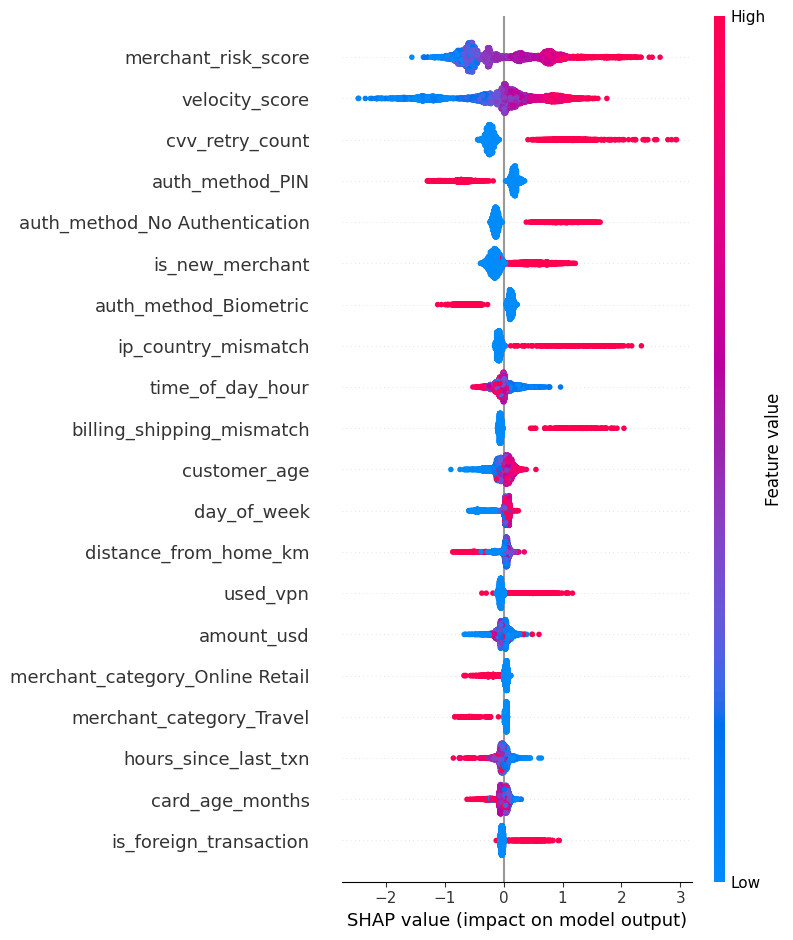


--- Local Explanation for a Single Transaction ---


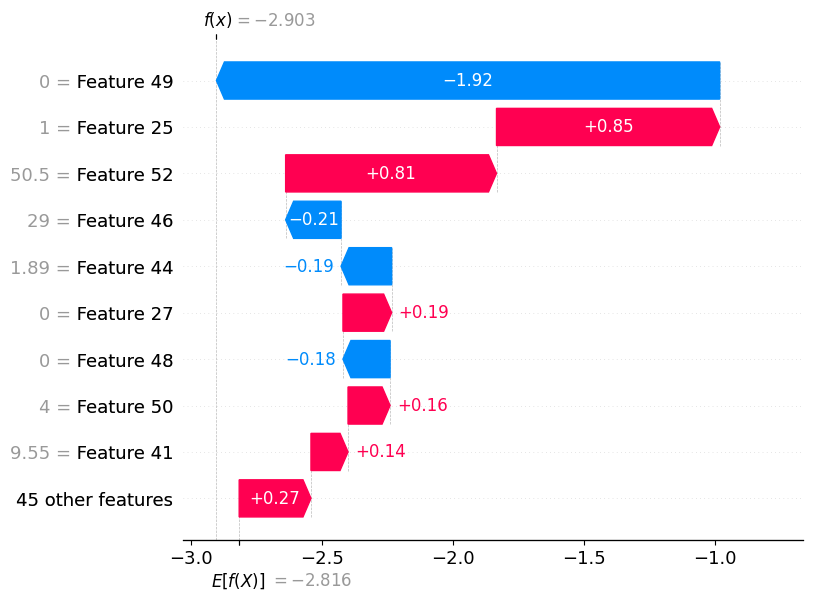

In [96]:
import shap
import pandas as pd

# 1. Initialize the SHAP TreeExplainer for your trained LightGBM model
explainer = shap.TreeExplainer(lgb_model)

# 2. Calculate SHAP values for your test set
# (Note: For binary classifiers, shap_values for LightGBM returns the values for the positive class)
shap_values = explainer(X_test_encoded)

# Clean feature names for clean plotting
feature_names = preprocessor.get_feature_names_out()
feature_names = [f.replace('cat__', '').replace(
    'bool__', '').replace('remainder__', '') for f in feature_names]
X_test_df = pd.DataFrame(X_test_encoded, columns=feature_names)

# 3. Global Summary Plot (Shows overall top features driving fraud predictions)
print("--- Global Feature Impact (SHAP Summary Plot) ---")
shap.summary_plot(shap_values, X_test_df)

# 4. Local Explanation (Explains why a SPECIFIC suspicious transaction was flagged)
# Let's pick the first transaction in your test set
print("\n--- Local Explanation for a Single Transaction ---")
shap.plots.waterfall(shap_values[0])

In [97]:
import pandas as pd
import numpy as np

# 1. Ensure shap_values is extracted (if not already done)
# shap_values = explainer(X_test_encoded)

# 2. Extract the raw SHAP values matrix (handles modern shap.Explanation objects)
shap_matrix = shap_values.values if hasattr(
    shap_values, 'values') else shap_values

# 3. Calculate mean absolute SHAP value for each feature
mean_abs_shap = np.abs(shap_matrix).mean(axis=0)

# 4. Create a clean DataFrame ranking the most important features
shap_importance_df = pd.DataFrame({
    'Feature': X_test_df.columns,
    'Mean Absolute SHAP Value': mean_abs_shap
}).sort_values(by='Mean Absolute SHAP Value', ascending=False).reset_index(drop=True)

# 5. Display the top 10 features
print("--- Top 10 Features Ranked by SHAP Importance ---")
display(shap_importance_df.head(10))

--- Top 10 Features Ranked by SHAP Importance ---


,Feature,Mean Absolute SHAP Value
0,merchant_risk_score,0.633143
1,velocity_score,0.488400
2,cvv_retry_count,0.383342
3,auth_method_PIN,0.293929
4,auth_method_No Authentication,0.242623
5,is_new_merchant,0.237184
6,auth_method_Biometric,0.193864
7,ip_country_mismatch,0.147297
8,time_of_day_hour,0.111799
9,billing_shipping_mismatch,0.105192


The model relies primarily on merchant risk history, transaction velocity, and CVV failure counts to separate fraud from normal behavior.

#### Models based on shap features

LightGMBM

In [98]:
import pandas as pd
import numpy as np
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, classification_report, precision_recall_curve

# 1. Define how many top features you want to keep
top_k = 10
selected_features = shap_importance_df['Feature'].head(top_k).tolist()

print(f"Retraining LightGBM using the top {top_k} features:")
print(selected_features)

# 2. Convert encoded arrays back to DataFrames (ensuring column names match)
feature_names = [f.replace('cat__', '').replace('bool__', '').replace(
    'remainder__', '') for f in preprocessor.get_feature_names_out()]
X_train_df = pd.DataFrame(X_train_encoded, columns=feature_names)
X_test_df = pd.DataFrame(X_test_encoded, columns=feature_names)

# 3. Filter datasets to only include the top features
X_train_subset = X_train_df[selected_features]
X_test_subset = X_test_df[selected_features]

# 4. Retrain LightGBM on the feature subset
lgb_subset_model = LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

lgb_subset_model.fit(X_train_subset, y_train)

# 5. Evaluate performance
y_prob_sub = lgb_subset_model.predict_proba(X_test_subset)[:, 1]
print(f"\nSubset Model ROC-AUC Score: {roc_auc_score(y_test, y_prob_sub):.4f}")

# Find optimal threshold for the subset model
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_sub)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold_sub = thresholds[np.argmax(f1_scores)]

y_pred_sub = (y_prob_sub >= best_threshold_sub).astype(int)
print(f"Optimal Threshold: {best_threshold_sub:.4f}")
print("\nClassification Report (Top Features Only):")
print(classification_report(y_test, y_pred_sub))

Retraining LightGBM using the top 10 features:
['merchant_risk_score', 'velocity_score', 'cvv_retry_count', 'auth_method_PIN', 'auth_method_No Authentication', 'is_new_merchant', 'auth_method_Biometric', 'ip_country_mismatch', 'time_of_day_hour', 'billing_shipping_mismatch']

Subset Model ROC-AUC Score: 0.8912
Optimal Threshold: 0.8281

Classification Report (Top Features Only):
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3932
           1       0.24      0.28      0.26        68

    accuracy                           0.97      4000
   macro avg       0.62      0.63      0.62      4000
weighted avg       0.97      0.97      0.97      4000



In [99]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

# 1. Full Feature Model Evaluation
y_prob_full = lgb_model.predict_proba(X_test_encoded)[:, 1]
roc_full = roc_auc_score(y_test, y_prob_full)

prec_f, rec_f, thresh_f = precision_recall_curve(y_test, y_prob_full)
f1_f = 2 * (prec_f * rec_f) / (prec_f + rec_f + 1e-10)
best_thresh_f = thresh_f[np.argmax(f1_f)]
y_pred_f = (y_prob_full >= best_thresh_f).astype(int)
p_f, r_f, f_f, _ = precision_recall_fscore_support(
    y_test, y_pred_f, average=None, zero_division=0)

# 2. Subset Feature Model Evaluation (Top Features)
y_prob_sub = lgb_subset_model.predict_proba(X_test_subset)[:, 1]
roc_sub = roc_auc_score(y_test, y_prob_sub)

prec_s, rec_s, thresh_s = precision_recall_curve(y_test, y_prob_sub)
f1_s = 2 * (prec_s * rec_s) / (prec_s + rec_s + 1e-10)
best_thresh_s = thresh_s[np.argmax(f1_s)]
y_pred_s = (y_prob_sub >= best_thresh_s).astype(int)
p_s, r_s, f_s, _ = precision_recall_fscore_support(
    y_test, y_pred_s, average=None, zero_division=0)

# 3. Compile into a Comparative Summary DataFrame
comparison_data = [
    {
        'Model Configuration': f'Full Features (All {X_test_encoded.shape[1]} features)',
        'ROC-AUC': round(roc_full, 4),
        'Opt Threshold': round(best_thresh_f, 4),
        'Fraud Precision': round(p_f[1], 4),
        'Fraud Recall': round(r_f[1], 4),
        'Fraud F1-Score': round(f_f[1], 4)
    },
    {
        'Model Configuration': f'Top-{len(selected_features)} Features (SHAP Selected)',
        'ROC-AUC': round(roc_sub, 4),
        'Opt Threshold': round(best_thresh_s, 4),
        'Fraud Precision': round(p_s[1], 4),
        'Fraud Recall': round(r_s[1], 4),
        'Fraud F1-Score': round(f_s[1], 4)
    }
]

comparison_df = pd.DataFrame(comparison_data)

print("--- Feature Reduction Performance Comparison ---")
display(comparison_df)

--- Feature Reduction Performance Comparison ---


,Model Configuration,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,Full Features (All 54 features),0.8953,0.6793,0.2474,0.3529,0.2909
1,Top-10 Features (SHAP Selected),0.8912,0.8281,0.2436,0.2794,0.2603


Random Forest

In [100]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve, classification_report

# 1. Initialize and train Random Forest on the top features subset
rf_subset_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=None,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_subset_model.fit(X_train_subset, y_train)

# 2. Predict probabilities on test subset
y_prob_rf_sub = rf_subset_model.predict_proba(X_test_subset)[:, 1]
print(
    f"Random Forest Subset ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf_sub):.4f}")

# 3. Find optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_rf_sub)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold_rf_sub = thresholds[np.argmax(f1_scores)]
print(f"Optimal Random Forest Threshold (Subset): {best_threshold_rf_sub:.4f}")

# 4. Apply threshold and print classification report
y_pred_rf_sub = (y_prob_rf_sub >= best_threshold_rf_sub).astype(int)
print("\nRandom Forest Classification Report (Top Features Only):")
print(classification_report(y_test, y_pred_rf_sub))

Random Forest Subset ROC-AUC Score: 0.8530
Optimal Random Forest Threshold (Subset): 0.2933

Random Forest Classification Report (Top Features Only):
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      3932
           1       0.20      0.32      0.25        68

    accuracy                           0.97      4000
   macro avg       0.60      0.65      0.62      4000
weighted avg       0.97      0.97      0.97      4000



In [101]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

# 1. Full Feature Random Forest Evaluation
y_prob_rf_full = rf_model.predict_proba(X_test_encoded)[:, 1]
roc_rf_full = roc_auc_score(y_test, y_prob_rf_full)

prec_rf_f, rec_rf_f, thresh_rf_f = precision_recall_curve(
    y_test, y_prob_rf_full)
f1_rf_f = 2 * (prec_rf_f * rec_rf_f) / (prec_rf_f + rec_rf_f + 1e-10)
best_thresh_rf_f = thresh_rf_f[np.argmax(f1_rf_f)]
y_pred_rf_f = (y_prob_rf_full >= best_thresh_rf_f).astype(int)
p_rf_f, r_rf_f, f_rf_f, _ = precision_recall_fscore_support(
    y_test, y_pred_rf_f, average=None, zero_division=0)

# 2. Subset Feature Random Forest Evaluation (Top Features)
y_prob_rf_sub = rf_subset_model.predict_proba(X_test_subset)[:, 1]
roc_rf_sub = roc_auc_score(y_test, y_prob_rf_sub)

prec_rf_s, rec_rf_s, thresh_rf_s = precision_recall_curve(
    y_test, y_prob_rf_sub)
f1_rf_s = 2 * (prec_rf_s * rec_rf_s) / (prec_rf_s + rec_rf_s + 1e-10)
best_thresh_rf_s = thresh_rf_s[np.argmax(f1_rf_s)]
y_pred_rf_s = (y_prob_rf_sub >= best_thresh_rf_s).astype(int)
p_rf_s, r_rf_s, f_rf_s, _ = precision_recall_fscore_support(
    y_test, y_pred_rf_s, average=None, zero_division=0)

# 3. Compile into a Comparative Summary DataFrame for Random Forest
comparison_data_rf = [
    {
        'Model Configuration': f'RF - Full Features (All {X_test_encoded.shape[1]} features)',
        'ROC-AUC': round(roc_rf_full, 4),
        'Opt Threshold': round(best_thresh_rf_f, 4),
        'Fraud Precision': round(p_rf_f[1], 4),
        'Fraud Recall': round(r_rf_f[1], 4),
        'Fraud F1-Score': round(f_rf_f[1], 4)
    },
    {
        'Model Configuration': f'RF - Top-{len(selected_features)} Features (SHAP Selected)',
        'ROC-AUC': round(roc_rf_sub, 4),
        'Opt Threshold': round(best_thresh_rf_s, 4),
        'Fraud Precision': round(p_rf_s[1], 4),
        'Fraud Recall': round(r_rf_s[1], 4),
        'Fraud F1-Score': round(f_rf_s[1], 4)
    }
]

comparison_rf_df = pd.DataFrame(comparison_data_rf)

print("--- Random Forest Feature Reduction Comparison ---")
display(comparison_rf_df)

--- Random Forest Feature Reduction Comparison ---


,Model Configuration,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,RF - Full Features (All 54 features),0.9064,0.1700,0.2000,0.3971,0.266
1,RF - Top-10 Features (SHAP Selected),0.8530,0.2933,0.2037,0.3235,0.250


Decision Tree

In [102]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support, classification_report

# 1. Initialize and train Decision Tree on the top features subset
dt_subset_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

dt_subset_model.fit(X_train_subset, y_train)

# 2. Predict probabilities on test subset
y_prob_dt_sub = dt_subset_model.predict_proba(X_test_subset)[:, 1]
print(
    f"Decision Tree Subset ROC-AUC Score: {roc_auc_score(y_test, y_prob_dt_sub):.4f}")

# 3. Find optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_dt_sub)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold_dt_sub = thresholds[np.argmax(
    f1_scores)] if len(thresholds) > 0 else 0.5
print(f"Optimal Decision Tree Threshold (Subset): {best_threshold_dt_sub:.4f}")

# 4. Apply threshold and print classification report
y_pred_dt_sub = (y_prob_dt_sub >= best_threshold_dt_sub).astype(int)
print("\nDecision Tree Classification Report (Top Features Only):")
print(classification_report(y_test, y_pred_dt_sub))

# --- 5. Comparative Evaluation (Full Features vs. Subset Features) ---
y_prob_dt_full = dt_model.predict_proba(X_test_encoded)[:, 1]
roc_dt_full = roc_auc_score(y_test, y_prob_dt_full)

prec_dt_f, rec_dt_f, thresh_dt_f = precision_recall_curve(
    y_test, y_prob_dt_full)
f1_dt_f = 2 * (prec_dt_f * rec_dt_f) / (prec_dt_f + rec_dt_f + 1e-10)
best_thresh_dt_f = thresh_dt_f[np.argmax(
    f1_dt_f)] if len(thresh_dt_f) > 0 else 0.5
y_pred_dt_f = (y_prob_dt_full >= best_thresh_dt_f).astype(int)
p_dt_f, r_dt_f, f_dt_f, _ = precision_recall_fscore_support(
    y_test, y_pred_dt_f, average=None, zero_division=0)

roc_dt_sub = roc_auc_score(y_test, y_prob_dt_sub)
p_dt_s, r_dt_s, f_dt_s, _ = precision_recall_fscore_support(
    y_test, y_pred_dt_sub, average=None, zero_division=0)

comparison_data_dt = [
    {
        'Model Configuration': f'DT - Full Features (All {X_test_encoded.shape[1]} features)',
        'ROC-AUC': round(roc_dt_full, 4),
        'Opt Threshold': round(best_thresh_dt_f, 4),
        'Fraud Precision': round(p_dt_f[1], 4) if len(p_dt_f) > 1 else 0.0,
        'Fraud Recall': round(r_dt_f[1], 4) if len(r_dt_f) > 1 else 0.0,
        'Fraud F1-Score': round(f_dt_f[1], 4) if len(f_dt_f) > 1 else 0.0
    },
    {
        'Model Configuration': f'DT - Top-{len(selected_features)} Features (SHAP Selected)',
        'ROC-AUC': round(roc_dt_sub, 4),
        'Opt Threshold': round(best_threshold_dt_sub, 4),
        'Fraud Precision': round(p_dt_s[1], 4) if len(p_dt_s) > 1 else 0.0,
        'Fraud Recall': round(r_dt_s[1], 4) if len(r_dt_s) > 1 else 0.0,
        'Fraud F1-Score': round(f_dt_s[1], 4) if len(f_dt_s) > 1 else 0.0
    }
]

comparison_dt_df = pd.DataFrame(comparison_data_dt)

print("\n--- Decision Tree Feature Reduction Comparison ---")
display(comparison_dt_df)

Decision Tree Subset ROC-AUC Score: 0.5605
Optimal Decision Tree Threshold (Subset): 1.0000

Decision Tree Classification Report (Top Features Only):
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3932
           1       0.17      0.13      0.15        68

    accuracy                           0.97      4000
   macro avg       0.58      0.56      0.57      4000
weighted avg       0.97      0.97      0.97      4000


--- Decision Tree Feature Reduction Comparison ---


,Model Configuration,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,DT - Full Features (All 54 features),0.5305,1.0,0.0926,0.0735,0.0820
1,DT - Top-10 Features (SHAP Selected),0.5605,1.0,0.1667,0.1324,0.1475


catboost

In [103]:
import pandas as pd
import numpy as np
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support, classification_report

# 1. Initialize and train CatBoost on the top features subset
cat_subset_model = CatBoostClassifier(
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=0
)

cat_subset_model.fit(X_train_subset, y_train)

# 2. Predict probabilities on test subset
y_prob_cat_sub = cat_subset_model.predict_proba(X_test_subset)[:, 1]
print(
    f"CatBoost Subset ROC-AUC Score: {roc_auc_score(y_test, y_prob_cat_sub):.4f}")

# 3. Find optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(
    y_test, y_prob_cat_sub)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold_cat_sub = thresholds[np.argmax(
    f1_scores)] if len(thresholds) > 0 else 0.5
print(f"Optimal CatBoost Threshold (Subset): {best_threshold_cat_sub:.4f}")

# 4. Apply threshold and print classification report
y_pred_cat_sub = (y_prob_cat_sub >= best_threshold_cat_sub).astype(int)
print("\nCatBoost Classification Report (Top Features Only):")
print(classification_report(y_test, y_pred_cat_sub))

# --- 5. Comparative Evaluation (Full Features vs. Subset Features) ---
y_prob_cat_full = cat_model.predict_proba(X_test_encoded)[:, 1]
roc_cat_full = roc_auc_score(y_test, y_prob_cat_full)

prec_cat_f, rec_cat_f, thresh_cat_f = precision_recall_curve(
    y_test, y_prob_cat_full)
f1_cat_f = 2 * (prec_cat_f * rec_cat_f) / (prec_cat_f + rec_cat_f + 1e-10)
best_thresh_cat_f = thresh_cat_f[np.argmax(
    f1_cat_f)] if len(thresh_cat_f) > 0 else 0.5
y_pred_cat_f = (y_prob_cat_full >= best_thresh_cat_f).astype(int)
p_cat_f, r_cat_f, f_cat_f, _ = precision_recall_fscore_support(
    y_test, y_pred_cat_f, average=None, zero_division=0
)

roc_cat_sub = roc_auc_score(y_test, y_prob_cat_sub)
p_cat_s, r_cat_s, f_cat_s, _ = precision_recall_fscore_support(
    y_test, y_pred_cat_sub, average=None, zero_division=0
)

comparison_data_cat = [
    {
        'Model Configuration': f'CatBoost - Full Features (All {X_test_encoded.shape[1]} features)',
        'ROC-AUC': round(roc_cat_full, 4),
        'Opt Threshold': round(best_thresh_cat_f, 4),
        'Fraud Precision': round(p_cat_f[1], 4) if len(p_cat_f) > 1 else 0.0,
        'Fraud Recall': round(r_cat_f[1], 4) if len(r_cat_f) > 1 else 0.0,
        'Fraud F1-Score': round(f_cat_f[1], 4) if len(f_cat_f) > 1 else 0.0
    },
    {
        'Model Configuration': f'CatBoost - Top-{len(selected_features)} Features (SHAP Selected)',
        'ROC-AUC': round(roc_cat_sub, 4),
        'Opt Threshold': round(best_threshold_cat_sub, 4),
        'Fraud Precision': round(p_cat_s[1], 4) if len(p_cat_s) > 1 else 0.0,
        'Fraud Recall': round(r_cat_s[1], 4) if len(r_cat_s) > 1 else 0.0,
        'Fraud F1-Score': round(f_cat_s[1], 4) if len(f_cat_s) > 1 else 0.0
    }
]

comparison_cat_df = pd.DataFrame(comparison_data_cat)

print("\n--- CatBoost Feature Reduction Comparison ---")
display(comparison_cat_df)

CatBoost Subset ROC-AUC Score: 0.8770
Optimal CatBoost Threshold (Subset): 0.3960

CatBoost Classification Report (Top Features Only):
              precision    recall  f1-score   support

           0       0.99      0.96      0.98      3932
           1       0.17      0.43      0.24        68

    accuracy                           0.95      4000
   macro avg       0.58      0.70      0.61      4000
weighted avg       0.98      0.95      0.96      4000


--- CatBoost Feature Reduction Comparison ---


,Model Configuration,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,CatBoost - Full Features (All 54 features),0.9337,0.7035,0.3197,0.5735,0.4105
1,CatBoost - Top-10 Features (SHAP Selected),0.8770,0.3960,0.1686,0.4265,0.2417


xgboost and ensemble

In [104]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support, classification_report

# 1. Train XGBoost on the subset features (if not already trained)
xgb_subset_model = XGBClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=98,  # accounting for 98% non-fraud imbalance
    random_state=42,
    n_jobs=-1
)
xgb_subset_model.fit(X_train_subset, y_train)

# 2. Get subset probabilities from all three ensemble members
y_prob_cat_sub = cat_subset_model.predict_proba(X_test_subset)[:, 1]
y_prob_xgb_sub = xgb_subset_model.predict_proba(X_test_subset)[:, 1]
y_prob_lgb_sub = lgb_subset_model.predict_proba(X_test_subset)[:, 1]

# 3. Average them for the Subset Voting Ensemble
y_prob_voting_sub = (y_prob_cat_sub + y_prob_xgb_sub + y_prob_lgb_sub) / 3

# 4. Evaluate Subset Voting Ensemble
roc_voting_sub = roc_auc_score(y_test, y_prob_voting_sub)
prec_v_s, rec_v_s, thresh_v_s = precision_recall_curve(
    y_test, y_prob_voting_sub)
f1_v_s = 2 * (prec_v_s * rec_v_s) / (prec_v_s + rec_v_s + 1e-10)
best_thresh_voting_sub = thresh_v_s[np.argmax(
    f1_v_s)] if len(thresh_v_s) > 0 else 0.5

y_pred_voting_sub = (y_prob_voting_sub >= best_thresh_voting_sub).astype(int)
p_v_s, r_v_s, f_v_s, _ = precision_recall_fscore_support(
    y_test, y_pred_voting_sub, average=None, zero_division=0)

print(f"Ensemble Voting Subset ROC-AUC Score: {roc_voting_sub:.4f}")
print(f"Optimal Voting Threshold (Subset): {best_thresh_voting_sub:.4f}")
print("\nClassification Report (Ensemble Voting - Top Features Only):")
print(classification_report(y_test, y_pred_voting_sub))

# --- 5. Comparative Evaluation (Full Features vs. Subset Features) ---
y_prob_voting_full = (
    cat_model.predict_proba(X_test_encoded)[:, 1] +
    xgb_model.predict_proba(X_test_encoded)[:, 1] +
    lgb_model.predict_proba(X_test_encoded)[:, 1]
) / 3

roc_voting_full = roc_auc_score(y_test, y_prob_voting_full)
prec_v_f, rec_v_f, thresh_v_f = precision_recall_curve(
    y_test, y_prob_voting_full)
f1_v_f = 2 * (prec_v_f * rec_v_f) / (prec_v_f + rec_v_f + 1e-10)
best_thresh_voting_full = thresh_v_f[np.argmax(
    f1_v_f)] if len(thresh_v_f) > 0 else 0.5

y_pred_voting_full = (y_prob_voting_full >=
                      best_thresh_voting_full).astype(int)
p_v_f, r_v_f, f_v_f, _ = precision_recall_fscore_support(
    y_test, y_pred_voting_full, average=None, zero_division=0)

comparison_data_voting = [
    {
        'Model Configuration': f'Ensemble - Full Features (All {X_test_encoded.shape[1]} features)',
        'ROC-AUC': round(roc_voting_full, 4),
        'Opt Threshold': round(best_thresh_voting_full, 4),
        'Fraud Precision': round(p_v_f[1], 4) if len(p_v_f) > 1 else 0.0,
        'Fraud Recall': round(r_v_f[1], 4) if len(r_v_f) > 1 else 0.0,
        'Fraud F1-Score': round(f_v_f[1], 4) if len(f_v_f) > 1 else 0.0
    },
    {
        'Model Configuration': f'Ensemble - Top-{len(selected_features)} Features (SHAP Selected)',
        'ROC-AUC': round(roc_voting_sub, 4),
        'Opt Threshold': round(best_thresh_voting_sub, 4),
        'Fraud Precision': round(p_v_s[1], 4) if len(p_v_s) > 1 else 0.0,
        'Fraud Recall': round(r_v_s[1], 4) if len(r_v_s) > 1 else 0.0,
        'Fraud F1-Score': round(f_v_s[1], 4) if len(f_v_s) > 1 else 0.0
    }
]

comparison_voting_df = pd.DataFrame(comparison_data_voting)

print("\n--- Ensemble Voting Feature Reduction Comparison ---")
display(comparison_voting_df)

Ensemble Voting Subset ROC-AUC Score: 0.8899
Optimal Voting Threshold (Subset): 0.6476

Classification Report (Ensemble Voting - Top Features Only):
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      3932
           1       0.20      0.40      0.27        68

    accuracy                           0.96      4000
   macro avg       0.60      0.68      0.62      4000
weighted avg       0.98      0.96      0.97      4000


--- Ensemble Voting Feature Reduction Comparison ---


,Model Configuration,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,Ensemble - Full Features (All 54 features),0.9176,0.6920,0.2778,0.3676,0.3165
1,Ensemble - Top-10 Features (SHAP Selected),0.8899,0.6476,0.2015,0.3971,0.2673


In [105]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

# Define all probability dictionaries for full vs subset models (including CatBoost)
evaluation_dict = {
    # --- Full Feature Models ---
    'Random Forest (Full)': rf_model.predict_proba(X_test_encoded)[:, 1],
    'LightGBM (Full)': lgb_model.predict_proba(X_test_encoded)[:, 1],
    'XGBoost (Full)': xgb_model.predict_proba(X_test_encoded)[:, 1],
    'CatBoost (Full)': cat_model.predict_proba(X_test_encoded)[:, 1],
    'Decision Tree (Full)': dt_model.predict_proba(X_test_encoded)[:, 1],
    'Ensemble Voting (Full)': (
        xgb_model.predict_proba(X_test_encoded)[:, 1] +
        lgb_model.predict_proba(X_test_encoded)[:, 1] +
        cat_model.predict_proba(X_test_encoded)[:, 1]
    ) / 4,

    # --- Top SHAP Feature Subset Models ---
    'Random Forest (Top SHAP)': rf_subset_model.predict_proba(X_test_subset)[:, 1],
    'LightGBM (Top SHAP)': lgb_subset_model.predict_proba(X_test_subset)[:, 1],
    'XGBoost (Top SHAP)': xgb_subset_model.predict_proba(X_test_subset)[:, 1],
    'CatBoost (Top SHAP)': cat_subset_model.predict_proba(X_test_subset)[:, 1],
    'Decision Tree (Top SHAP)': dt_subset_model.predict_proba(X_test_subset)[:, 1],
    'Ensemble Voting (Top SHAP)': (
        xgb_subset_model.predict_proba(X_test_subset)[:, 1] +
        lgb_subset_model.predict_proba(X_test_subset)[:, 1] +
        cat_subset_model.predict_proba(X_test_subset)[:, 1]
    ) / 4
}

results = []

for name, y_prob in evaluation_dict.items():
    # 1. Calculate ROC-AUC
    roc_auc = roc_auc_score(y_test, y_prob)

    # 2. Find optimal decision threshold maximizing F1-score
    precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(
        thresholds) else 0.5

    # 3. Apply threshold
    y_pred = (y_prob >= best_threshold).astype(int)

    # 4. Extract metrics for Class 1 (Fraud)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average=None, zero_division=0)

    fraud_precision = precision[1] if len(precision) > 1 else 0.0
    fraud_recall = recall[1] if len(recall) > 1 else 0.0
    fraud_f1 = f1[1] if len(f1) > 1 else 0.0

    # Store results
    results.append({
        'Model Configuration': name,
        'ROC-AUC': round(roc_auc, 4),
        'Opt Threshold': round(best_threshold, 4),
        'Fraud Precision': round(fraud_precision, 4),
        'Fraud Recall': round(fraud_recall, 4),
        'Fraud F1-Score': round(fraud_f1, 4)
    })

# Convert to DataFrame and sort by Fraud Recall (descending)
master_summary_df = pd.DataFrame(results).sort_values(
    by=['Fraud Recall', 'ROC-AUC'], ascending=False).reset_index(drop=True)

print("--- Master Model Performance Comparison: Full vs. SHAP Features ---")
display(master_summary_df)

--- Master Model Performance Comparison: Full vs. SHAP Features ---


,Model Configuration,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,CatBoost (Full),0.9337,0.7035,0.3197,0.5735,0.4105
1,CatBoost (Top SHAP),0.8770,0.3960,0.1686,0.4265,0.2417
2,Random Forest (Full),0.9064,0.1700,0.2000,0.3971,0.2660
3,Ensemble Voting (Top SHAP),0.8899,0.4857,0.2015,0.3971,0.2673
4,Ensemble Voting (Full),0.9176,0.5190,0.2778,0.3676,0.3165
5,LightGBM (Full),0.8953,0.6793,0.2474,0.3529,0.2909
6,XGBoost (Full),0.8820,0.6598,0.2292,0.3235,0.2683
7,XGBoost (Top SHAP),0.8787,0.8433,0.2157,0.3235,0.2588
8,Random Forest (Top SHAP),0.8530,0.2933,0.2037,0.3235,0.2500
9,LightGBM (Top SHAP),0.8912,0.8281,0.2436,0.2794,0.2603


In [106]:
import pandas as pd
import numpy as np

# 1. Select a random index from the test set
random_idx = np.random.randint(0, len(y_test))

# Extract the actual true label for this transaction
true_label = y_test.iloc[random_idx] if hasattr(
    y_test, 'iloc') else y_test[random_idx]

# Safely extract a single row (preserving 2D shape with 1 sample)
if isinstance(X_test_encoded, np.ndarray):
    x_full_row = X_test_encoded[random_idx:random_idx+1]
else:
    x_full_row = X_test_encoded.iloc[[random_idx]]

x_sub_row = X_test_subset.iloc[[random_idx]]

print(f"Selected Random Test Transaction Index: {random_idx}")
print(
    f"True Transaction Status: {'FRAUD' if true_label == 1 else 'NORMAL'}\n")

# 2. Define all models, their corresponding data rows, and their optimal thresholds
inference_models = [
    # Full Feature Models
    {'Name': 'LightGBM (Full)', 'Model': lgb_model,
     'Data': x_full_row, 'Threshold': best_thresh_f},
    {'Name': 'Random Forest (Full)', 'Model': rf_model,
     'Data': x_full_row, 'Threshold': best_thresh_rf_f},
    {'Name': 'XGBoost (Full)', 'Model': xgb_model,
     'Data': x_full_row, 'Threshold': best_thresh_rf_f},
    {'Name': 'Decision Tree (Full)', 'Model': dt_model,
     'Data': x_full_row, 'Threshold': best_thresh_dt_f},
    {'Name': 'Ensemble Voting (Full)', 'Model': None, 'Data': x_full_row,
     'Threshold': best_thresh_voting_full, 'IsEnsemble': True, 'Type': 'Full'},

    # Top SHAP Feature Subset Models
    {'Name': 'LightGBM (Top SHAP)', 'Model': lgb_subset_model,
     'Data': x_sub_row, 'Threshold': best_thresh_s},
    {'Name': 'Random Forest (Top SHAP)', 'Model': rf_subset_model,
     'Data': x_sub_row, 'Threshold': best_threshold_rf_sub},
    {'Name': 'XGBoost (Top SHAP)', 'Model': xgb_subset_model,
     'Data': x_sub_row, 'Threshold': 0.5},
    {'Name': 'Decision Tree (Top SHAP)', 'Model': dt_subset_model,
     'Data': x_sub_row, 'Threshold': best_threshold_dt_sub},
    {'Name': 'Ensemble Voting (Top SHAP)', 'Model': None, 'Data': x_sub_row,
     'Threshold': best_thresh_voting_sub, 'IsEnsemble': True, 'Type': 'Subset'}
]

results = []

for item in inference_models:
    if item.get('IsEnsemble'):
        if item['Type'] == 'Full':
            prob = (
                rf_model.predict_proba(x_full_row)[:, 1] +
                xgb_model.predict_proba(x_full_row)[:, 1] +
                lgb_model.predict_proba(x_full_row)[:, 1]
            )[0] / 3
        else:
            prob = (
                rf_subset_model.predict_proba(x_sub_row)[:, 1] +
                xgb_subset_model.predict_proba(x_sub_row)[:, 1] +
                lgb_subset_model.predict_proba(x_sub_row)[:, 1]
            )[0] / 3
    else:
        prob = item['Model'].predict_proba(item['Data'])[:, 1][0]

    thresh = item['Threshold']
    pred = 1 if prob >= thresh else 0
    correct = (pred == true_label)

    results.append({
        'Model Configuration': item['Name'],
        'Fraud Probability': round(float(prob), 4),
        'Decision Threshold': round(float(thresh), 4),
        'Prediction': 'FRAUD' if pred == 1 else 'NORMAL',
        'Correct?':  'Yes' if correct else 'No'
    })

# 3. Compile and display summary table
prediction_summary_df = pd.DataFrame(results)
display(prediction_summary_df)

Selected Random Test Transaction Index: 3303
True Transaction Status: NORMAL



,Model Configuration,Fraud Probability,Decision Threshold,Prediction,Correct?
0,LightGBM (Full),0.4638,0.6793,NORMAL,Yes
1,Random Forest (Full),0.0700,0.1700,NORMAL,Yes
2,XGBoost (Full),0.1979,0.1700,FRAUD,No
3,Decision Tree (Full),1.0000,1.0000,FRAUD,No
4,Ensemble Voting (Full),0.2439,0.6920,NORMAL,Yes
5,LightGBM (Top SHAP),0.2821,0.8281,NORMAL,Yes
6,Random Forest (Top SHAP),0.0333,0.2933,NORMAL,Yes
7,XGBoost (Top SHAP),0.3152,0.5000,NORMAL,Yes
8,Decision Tree (Top SHAP),0.0000,1.0000,NORMAL,Yes
9,Ensemble Voting (Top SHAP),0.2102,0.6476,NORMAL,Yes


In [107]:
import pandas as pd
import numpy as np

# 1. Find indices in the test set where the true label is explicitly FRAUD (1)
y_test_array = y_test.to_numpy() if hasattr(
    y_test, 'to_numpy') else np.array(y_test)
fraud_indices = np.where(y_test_array == 1)[0]

if len(fraud_indices) == 0:
    print("No fraud cases found in y_test! Check your test split or class balance.")
else:
    # Pick a random fraud index from the available ones
    random_fraud_idx = np.random.choice(fraud_indices)
    true_label = 1

    # Safely extract a single row for full features and subset features
    if isinstance(X_test_encoded, np.ndarray):
        x_full_row = X_test_encoded[random_fraud_idx:random_fraud_idx+1]
    else:
        x_full_row = X_test_encoded.iloc[[random_fraud_idx]]

    x_sub_row = X_test_subset.iloc[[random_fraud_idx]]

    print(f"Selected Fraud Test Transaction Index: {random_fraud_idx}")
    print(f"True Transaction Status: FRAUD\n")

    # 2. Define all models, their data rows, and optimal decision thresholds
    inference_models = [
        # Full Feature Models
        {'Name': 'LightGBM (Full)', 'Model': lgb_model,
         'Data': x_full_row, 'Threshold': best_thresh_f},
        {'Name': 'Random Forest (Full)', 'Model': rf_model,
         'Data': x_full_row, 'Threshold': best_thresh_rf_f},
        {'Name': 'XGBoost (Full)', 'Model': xgb_model,
         'Data': x_full_row, 'Threshold': best_thresh_rf_f},
        {'Name': 'Decision Tree (Full)', 'Model': dt_model,
         'Data': x_full_row, 'Threshold': best_thresh_dt_f},
        {'Name': 'Ensemble Voting (Full)', 'Model': None, 'Data': x_full_row,
         'Threshold': best_thresh_voting_full, 'IsEnsemble': True, 'Type': 'Full'},

        # Top SHAP Feature Subset Models
        {'Name': 'LightGBM (Top SHAP)', 'Model': lgb_subset_model,
         'Data': x_sub_row, 'Threshold': best_thresh_s},
        {'Name': 'Random Forest (Top SHAP)', 'Model': rf_subset_model,
         'Data': x_sub_row, 'Threshold': best_threshold_rf_sub},
        {'Name': 'XGBoost (Top SHAP)', 'Model': xgb_subset_model,
         'Data': x_sub_row, 'Threshold': 0.5},
        {'Name': 'Decision Tree (Top SHAP)', 'Model': dt_subset_model,
         'Data': x_sub_row, 'Threshold': best_threshold_dt_sub},
        {'Name': 'Ensemble Voting (Top SHAP)', 'Model': None, 'Data': x_sub_row,
         'Threshold': best_thresh_voting_sub, 'IsEnsemble': True, 'Type': 'Subset'}
    ]

    results = []

    for item in inference_models:
        if item.get('IsEnsemble'):
            if item['Type'] == 'Full':
                prob = (
                    rf_model.predict_proba(x_full_row)[:, 1] +
                    xgb_model.predict_proba(x_full_row)[:, 1] +
                    lgb_model.predict_proba(x_full_row)[:, 1]
                )[0] / 3
            else:
                prob = (
                    rf_subset_model.predict_proba(x_sub_row)[:, 1] +
                    xgb_subset_model.predict_proba(x_sub_row)[:, 1] +
                    lgb_subset_model.predict_proba(x_sub_row)[:, 1]
                )[0] / 3
        else:
            prob = item['Model'].predict_proba(item['Data'])[:, 1][0]

        thresh = item['Threshold']
        pred = 1 if prob >= thresh else 0
        correct = (pred == true_label)

        results.append({
            'Model Configuration': item['Name'],
            'Fraud Probability': round(float(prob), 4),
            'Decision Threshold': round(float(thresh), 4),
            'Prediction': 'FRAUD' if pred == 1 else 'NORMAL',
            'Correct?': 'Yes' if correct else 'No'
        })

    # 3. Compile and display summary table
    fraud_prediction_df = pd.DataFrame(results)
    display(fraud_prediction_df)

Selected Fraud Test Transaction Index: 1076
True Transaction Status: FRAUD



,Model Configuration,Fraud Probability,Decision Threshold,Prediction,Correct?
0,LightGBM (Full),0.2081,0.6793,NORMAL,No
1,Random Forest (Full),0.1200,0.1700,NORMAL,No
2,XGBoost (Full),0.4290,0.1700,FRAUD,Yes
3,Decision Tree (Full),0.0000,1.0000,NORMAL,No
4,Ensemble Voting (Full),0.2524,0.6920,NORMAL,No
5,LightGBM (Top SHAP),0.2724,0.8281,NORMAL,No
6,Random Forest (Top SHAP),0.1200,0.2933,NORMAL,No
7,XGBoost (Top SHAP),0.3143,0.5000,NORMAL,No
8,Decision Tree (Top SHAP),0.0000,1.0000,NORMAL,No
9,Ensemble Voting (Top SHAP),0.2356,0.6476,NORMAL,No


isolation forest (Unsupervised)

In [108]:
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import IsolationForest
import numpy as np
import pandas as pd

# Initialize Isolation Forest
# contamination=0.02 approximates your known fraud rate (~2%)
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

# Fit on training data (unsupervised, doesn't use y_train)
iso_forest.fit(X_train_encoded)
# Get raw decision function scores for test set
raw_iso_scores = iso_forest.decision_function(X_test_encoded)

# Invert and normalize to a 0 to 1 risk score (higher = weirder/more risky)
iso_risk_score = 1 - (raw_iso_scores - raw_iso_scores.min()) / \
    (raw_iso_scores.max() - raw_iso_scores.min())
# Choose your weights (e.g., 70% Supervised power + 30% Unsupervised anomaly detection)
alpha = 0.7

# Assume y_prob_supervised is your best model's probability output (e.g., CatBoost or Ensemble)
hybrid_score = (alpha * y_prob_cat_full) + ((1 - alpha) * iso_risk_score)

# Evaluate the new Hybrid score using your existing evaluation logic
print(f"Supervised ROC-AUC: {roc_auc_score(y_test, y_prob_cat_full):.4f}")
print(f"Hybrid Score ROC-AUC: {roc_auc_score(y_test, hybrid_score):.4f}")

Supervised ROC-AUC: 0.9337
Hybrid Score ROC-AUC: 0.9422


In [109]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

# Assuming y_test, y_prob_supervised, and hybrid_score are already defined in your workspace

# 1. Evaluate Pure Supervised Model
roc_sup = roc_auc_score(y_test, y_prob_cat_full)
prec_sup, rec_sup, thresh_sup = precision_recall_curve(
    y_test, y_prob_cat_full)
f1_sup = 2 * (prec_sup * rec_sup) / (prec_sup + rec_sup + 1e-10)
best_idx_sup = np.argmax(f1_sup)
best_thresh_sup = thresh_sup[best_idx_sup] if best_idx_sup < len(
    thresh_sup) else 0.5

y_pred_sup = (y_prob_cat_full >= best_thresh_sup).astype(int)
p_sup, r_sup, f_sup, _ = precision_recall_fscore_support(
    y_test, y_pred_sup, average=None, zero_division=0
)

# 2. Evaluate Hybrid Score Model (Supervised + Unsupervised Anomaly)
roc_hyb = roc_auc_score(y_test, hybrid_score)
prec_hyb, rec_hyb, thresh_hyb = precision_recall_curve(y_test, hybrid_score)
f1_hyb = 2 * (prec_hyb * rec_hyb) / (prec_hyb + rec_hyb + 1e-10)
best_idx_hyb = np.argmax(f1_hyb)
best_thresh_hyb = thresh_hyb[best_idx_hyb] if best_idx_hyb < len(
    thresh_hyb) else 0.5

y_pred_hyb = (hybrid_score >= best_thresh_hyb).astype(int)
p_hyb, r_hyb, f_hyb, _ = precision_recall_fscore_support(
    y_test, y_pred_hyb, average=None, zero_division=0
)

# 3. Compile Comparative Summary DataFrame
comparison_data = [
    {
        'Model Strategy': 'Pure Supervised Model',
        'ROC-AUC': round(roc_sup, 4),
        'Opt Threshold': round(best_thresh_sup, 4),
        'Fraud Precision': round(p_sup[1], 4) if len(p_sup) > 1 else 0.0,
        'Fraud Recall': round(r_sup[1], 4) if len(r_sup) > 1 else 0.0,
        'Fraud F1-Score': round(f_sup[1], 4) if len(f_sup) > 1 else 0.0
    },
    {
        'Model Strategy': 'Hybrid Score (Supervised + Isolation Forest)',
        'ROC-AUC': round(roc_hyb, 4),
        'Opt Threshold': round(best_thresh_hyb, 4),
        'Fraud Precision': round(p_hyb[1], 4) if len(p_hyb) > 1 else 0.0,
        'Fraud Recall': round(r_hyb[1], 4) if len(r_hyb) > 1 else 0.0,
        'Fraud F1-Score': round(f_hyb[1], 4) if len(f_hyb) > 1 else 0.0
    }
]

comparison_df = pd.DataFrame(comparison_data)

print("--- Supervised vs. Hybrid Model Performance Comparison ---")
display(comparison_df)

--- Supervised vs. Hybrid Model Performance Comparison ---


,Model Strategy,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,Pure Supervised Model,0.9337,0.7035,0.3197,0.5735,0.4105
1,Hybrid Score (Supervised + Isolation Forest),0.9422,0.6370,0.3212,0.6471,0.4293


In [110]:
def find_optimal_business_threshold(y_true, y_prob, cost_fn=15, cost_fp=150):
    """
    Finds the threshold that minimizes total financial cost.
    - cost_fp (False Positive): Customer friction / lost good sale cost
    - cost_fn (False Negative): Chargeback / fraud loss cost
    """
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)

    best_thresh = 0.5
    min_cost = float('inf')

    # Evaluate a range of thresholds
    for thresh in np.linspace(0.01, 0.99, 200):
        y_pred = (y_prob >= thresh).astype(int)

        # Calculate confusion matrix components manually to avoid shape mismatches
        fp = np.sum((y_pred == 1) & (y_true == 0))
        fn = np.sum((y_pred == 0) & (y_true == 1))

        total_cost = (fp * cost_fp) + (fn * cost_fn)

        if total_cost < min_cost:
            min_cost = total_cost
            best_thresh = thresh

    return best_thresh


# Calculate your dollar-optimized threshold for the hybrid model
optimal_biz_thresh = find_optimal_business_threshold(
    y_test, hybrid_score, cost_fn=200, cost_fp=20)
print(f"Optimal Business-Cost Threshold: {optimal_biz_thresh:.4f}")

Optimal Business-Cost Threshold: 0.6157
